# STGCN para datos semanales por departamento

Notebook autocontenido basado en el código de este repositorio. Conserva las capas STGCN, el procesamiento de la adyacencia, la división temporal 70/15/15, la transformación log1p, el z-score ajustado solo con entrenamiento, el ventaneo, early stopping y las métricas MSE, MAE, RMSE y WMAPE.

En Kaggle, agrega tu dataset como input y ajusta `DATA_DIR` en la siguiente celda. Debe contener `casos.csv` y `adj.npy` o `adj.npz`. El CSV puede incluir `semana_inicio`; esa columna se excluye y las demás deben ser las 33 columnas de departamentos en el mismo orden de la matriz.


In [1]:
# Imports y configuración de datos
import os
import gc
import math
import random
import warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import norm
from sklearn import preprocessing
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data_utils
import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Kaggle: cambia esta ruta por la carpeta que aparece en /kaggle/input.
DATA_DIR = Path('/kaggle/input/mis-datos')
CASE_FILE = '/kaggle/input/datasets/camijope/stgcn-dengue/casos_hasta_2022-12-31.csv'
ADJ_NPY_FILE = '/kaggle/input/datasets/camijope/stgcn-dengue/adj.npy'
ADJ_NPZ_FILE = 'adj.npz'

# Hiperparámetros: mismos valores predeterminados que main.py del proyecto.
CONFIG = dict(
    seed=42, 
    n_his=12, 
    n_pred=9, 
    time_intvl=5, 
    Kt=3, 
    stblock_num=1, #2
    act_func='glu', 
    Ks=3, 
    graph_conv_type='cheb_graph_conv',
    gso_type='sym_norm_lap', 
    enable_bias=True, 
    droprate=0.3, #0.5
    lr=0.0003, #0.001
    weight_decay_rate=0.01, #0.001
    batch_size=16, #32
    epochs=1000,
    opt='adamw', 
    step_size=10, 
    gamma=0.95, 
    patience=25, #10
    train_val_test=(0.70, 0.15, 0.15),
)

def set_env(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_env(CONFIG['seed'])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
else:
    gc.collect()
print('Device:', DEVICE)
print('Data folder:', DATA_DIR)


Device: cpu
Data folder: /kaggle/input/mis-datos


## Cargador, preprocesamiento de grafo y métricas

In [2]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch

def load_adj(dataset_name):
    dataset_path = os.path.join('./data', dataset_name)
    npz_path = os.path.join(dataset_path, 'adj.npz')
    npy_path = os.path.join(dataset_path, 'adj.npy')

    if os.path.exists(npz_path):
        adj = sp.load_npz(npz_path).tocsc()
    elif os.path.exists(npy_path):
        # También permite matrices densas guardadas con numpy.
        adj = sp.csc_matrix(np.load(npy_path))
    else:
        raise FileNotFoundError(
            f'No se encontró adj.npz ni adj.npy en {dataset_path}.'
        )

    if adj.shape[0] != adj.shape[1]:
        raise ValueError(f'La matriz de adyacencia debe ser cuadrada; tiene forma {adj.shape}.')

    n_vertex = adj.shape[0]
    return adj, n_vertex


def load_data(dataset_name, len_train, len_val):
    dataset_path = os.path.join('./data', dataset_name)
    data_file = 'casos.csv' if dataset_name == 'mis_datos' else 'vel.csv'
    vel = pd.read_csv(os.path.join(dataset_path, data_file))

    # La fecha identifica cada fila; no es un nodo del grafo.
    if dataset_name == 'mis_datos' and 'semana_inicio' in vel.columns:
        vel = vel.drop(columns=['semana_inicio'])

    # El archivo debe tener solo las columnas numéricas de los nodos.
    vel = vel.apply(pd.to_numeric, errors='raise')

    train = vel.iloc[:len_train].to_numpy(dtype=np.float32)
    val = vel.iloc[len_train:len_train + len_val].to_numpy(dtype=np.float32)
    test = vel.iloc[len_train + len_val:].to_numpy(dtype=np.float32)

    return train, val, test


def data_transform(data, n_his, n_pred, device):
    data = np.asarray(data, dtype=np.float32)
    n_vertex = data.shape[1]
    len_record = len(data)

    # +1 incluye la última ventana válida.
    num = len_record - n_his - n_pred + 1
    if num <= 0:
        raise ValueError(
            f'No hay suficientes filas ({len_record}) para n_his={n_his} '
            f'y n_pred={n_pred}.'
        )

    x = np.zeros((num, 1, n_his, n_vertex), dtype=np.float32)
    y = np.zeros((num, n_vertex), dtype=np.float32)

    for i in range(num):
        x[i, 0, :, :] = data[i:i + n_his]
        y[i] = data[i + n_his + n_pred - 1]

    return torch.from_numpy(x).to(device), torch.from_numpy(y).to(device)


In [3]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import norm
import torch

def calc_gso(dir_adj, gso_type):
    n_vertex = dir_adj.shape[0]

    if sp.issparse(dir_adj) == False:
        dir_adj = sp.csc_matrix(dir_adj)
    elif dir_adj.format != 'csc':
        dir_adj = dir_adj.tocsc()

    id = sp.identity(n_vertex, format='csc')

    # Symmetrizing an adjacency matrix
    adj = dir_adj + dir_adj.T.multiply(dir_adj.T > dir_adj) - dir_adj.multiply(dir_adj.T > dir_adj)
    #adj = 0.5 * (dir_adj + dir_adj.transpose())
    
    if gso_type == 'sym_renorm_adj' or gso_type == 'rw_renorm_adj' \
        or gso_type == 'sym_renorm_lap' or gso_type == 'rw_renorm_lap':
        adj = adj + id
    
    if gso_type == 'sym_norm_adj' or gso_type == 'sym_renorm_adj' \
        or gso_type == 'sym_norm_lap' or gso_type == 'sym_renorm_lap':
        row_sum = adj.sum(axis=1).A1
        row_sum_inv_sqrt = np.power(row_sum, -0.5)
        row_sum_inv_sqrt[np.isinf(row_sum_inv_sqrt)] = 0.
        deg_inv_sqrt = sp.diags(row_sum_inv_sqrt, format='csc')
        # A_{sym} = D^{-0.5} * A * D^{-0.5}
        sym_norm_adj = deg_inv_sqrt.dot(adj).dot(deg_inv_sqrt)

        if gso_type == 'sym_norm_lap' or gso_type == 'sym_renorm_lap':
            sym_norm_lap = id - sym_norm_adj
            gso = sym_norm_lap
        else:
            gso = sym_norm_adj

    elif gso_type == 'rw_norm_adj' or gso_type == 'rw_renorm_adj' \
        or gso_type == 'rw_norm_lap' or gso_type == 'rw_renorm_lap':
        row_sum = np.sum(adj, axis=1).A1
        row_sum_inv = np.power(row_sum, -1)
        row_sum_inv[np.isinf(row_sum_inv)] = 0.
        deg_inv = np.diag(row_sum_inv)
        # A_{rw} = D^{-1} * A
        rw_norm_adj = deg_inv.dot(adj)

        if gso_type == 'rw_norm_lap' or gso_type == 'rw_renorm_lap':
            rw_norm_lap = id - rw_norm_adj
            gso = rw_norm_lap
        else:
            gso = rw_norm_adj

    else:
        raise ValueError(f'{gso_type} is not defined.')

    return gso

def calc_chebynet_gso(gso):
    if sp.issparse(gso) == False:
        gso = sp.csc_matrix(gso)
    elif gso.format != 'csc':
        gso = gso.tocsc()

    id = sp.identity(gso.shape[0], format='csc')
    # If you encounter a NotImplementedError, please update your scipy version to 1.10.1 or later.
    eigval_max = norm(gso, 2)

    # If the gso is symmetric or random walk normalized Laplacian,
    # then the maximum eigenvalue is smaller than or equals to 2.
    if eigval_max >= 2:
        gso = gso - id
    else:
        gso = 2 * gso / eigval_max - id

    return gso

def cnv_sparse_mat_to_coo_tensor(sp_mat, device):
    # convert a compressed sparse row (csr) or compressed sparse column (csc) matrix to a hybrid sparse coo tensor
    sp_coo_mat = sp_mat.tocoo()
    i = torch.from_numpy(np.vstack((sp_coo_mat.row, sp_coo_mat.col)))
    v = torch.from_numpy(sp_coo_mat.data)
    s = torch.Size(sp_coo_mat.shape)

    if sp_mat.dtype == np.float32 or sp_mat.dtype == np.float64:
        return torch.sparse_coo_tensor(indices=i, values=v, size=s, dtype=torch.float32, device=device, requires_grad=False)
    else:
        raise TypeError(f'ERROR: The dtype of {sp_mat} is {sp_mat.dtype}, not been applied in implemented models.')

def evaluate_model(model, loss, data_iter):
    model.eval()
    l_sum, n = 0.0, 0
    with torch.no_grad():
        for x, y in data_iter:
            y_pred = model(x).view(len(x), -1)
            l = loss(y_pred, y)
            l_sum += l.item() * y.shape[0]
            n += y.shape[0]
        mse = l_sum / n
        
        return mse

def inverse_log_zscore(values_scaled, scaler):
    """Convierte valores Z-score de log1p de vuelta a escala de casos."""
    values_log = scaler.inverse_transform(values_scaled)
    return np.expm1(values_log)

def evaluate_metric(model, data_iter, scaler):
    model.eval()
    y_true_all, y_pred_all = [], []
    with torch.no_grad():
        for x, y in data_iter:
            y_true_scaled = y.cpu().numpy()
            y_pred_scaled = model(x).view(len(x), -1).cpu().numpy()
            y_true_all.append(inverse_log_zscore(y_true_scaled, scaler))
            y_pred_all.append(inverse_log_zscore(y_pred_scaled, scaler))

    y_true = np.concatenate(y_true_all, axis=0)
    y_pred = np.concatenate(y_pred_all, axis=0)
    error = np.abs(y_true - y_pred)
    MSE = np.mean((y_true - y_pred) ** 2)
    MAE = np.mean(error)
    RMSE = np.sqrt(MSE)
    WMAPE = np.sum(error) / (np.sum(np.abs(y_true)) + 1e-5)
    return MSE, MAE, RMSE, WMAPE


## Early stopping y optimizador Lion

In [4]:
import math
import torch

class EarlyStopping:
    """Early stops the training if validation loss doesn't improve after a given patience."""
    def __init__(self, delta: float = 0.0, patience: int = 7, verbose: bool = True, path: str = 'checkpoint.pt'):
        """
        Args:
            patience (int): How long to wait after last time validation loss improved.
                            Default: 7
            verbose (bool): If True, prints a message for each validation loss improvement. 
                            Default: False
            delta (float): Minimum change in the monitored quantity to qualify as an improvement.
                            Default: 0
            path (str): Path for the checkpoint to be saved to.
                            Default: 'checkpoint.pt'           
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = math.inf
        self.delta = delta
        self.path = path

    def __call__(self, val_loss, model):

        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score <= self.best_score + self.delta:
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.4f} --> {val_loss:.4f}). Saving model...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

In [5]:
import torch
from torch import Tensor
from torch.optim.optimizer import Optimizer
from typing import Any, Iterable, Dict, Union, TypeAlias


ParamsT: TypeAlias = Union[Iterable[torch.Tensor], Iterable[Dict[str, Any]]]


class Lion(Optimizer):
    r"""Implements Lion algorithm."""

    def __init__(self, params, lr: Union[float, Tensor] = 1e-3, betas=(0.9, 0.99), weight_decay: float = 1e-2):
        """Initialize the hyperparameters.

        Args:
            params (iterable): iterable of parameters to optimize or dicts defining 
                parameter groups
            lr (float, optional): learning rate (default: 1e-4)
            betas (Tuple[float, float], optional): coefficients used for computing 
                running averages of gradient and its square (default: (0.9, 0.99))
            weight_decay (float, optional): weight decay coefficient (default: 0)
        """

        if not 0.0 <= lr:
            raise ValueError('Invalid learning rate: {}'.format(lr))
        if not 0.0 <= betas[0] < 1.0:
            raise ValueError('Invalid beta parameter at index 0: {}'.format(betas[0]))
        if not 0.0 <= betas[1] < 1.0:
            raise ValueError('Invalid beta parameter at index 1: {}'.format(betas[1]))
        defaults = dict(lr = lr, betas = betas, weight_decay = weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        """Performs a single optimization step.

        Args:
            closure (callable, optional): A closure that reevaluates the model 
                and returns the loss.

        Returns: 
            the loss.
        """
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue

                # Perform stepweight decay
                p.data.mul_(1 - group['lr'] * group['weight_decay'])

                grad = p.grad
                state = self.state[p]
                # State initialization
                if len(state) == 0:
                    # Exponential moving average of gradient values
                    state['exp_avg'] = torch.zeros_like(p)

                exp_avg = state['exp_avg']
                beta1, beta2 = group['betas']

                # Weight update
                update = exp_avg * beta1 + grad * (1 - beta1)

                p.add_(update.sign_(), alpha = -group['lr'])

                # Decay the momentum running average coefficient
                exp_avg.mul_(beta2).add_(grad, alpha = 1 - beta2)

        return loss


class Tiger(Optimizer):
    r"""Tiger Optimizer
        A PyTorch implementation of the Tiger optimizer based on 
        https://github.com/google/automl/blob/master/lion/lion_pytorch.py
    """

    def __init__(
        self, 
        params: ParamsT,
        lr: Union[float, Tensor] = 1e-3, 
        beta: float = 0.965, 
        weight_decay: float = 1e-2):
        """Initialize the hyperparameters.
        Args:
            params (iterable): iterable of parameters to optimize or dicts defining 
              parameter groups
            lr (float, optional): learning rate (default: 1e-3)
            beta (float, float], optional): coefficients used for computing running 
              averages of gradient and its square (default: 0.965)
            weight_decay (float, optional): weight decay coefficient (default: 0.01)
        """
        if not 0.0 <= lr:
            raise ValueError('Invalid learning rate: {lr}')
        if not 0.0 <= beta < 1.0:
            raise ValueError('Invalid beta parameter: {beta}')
        if not 0.0 <= weight_decay:
            raise ValueError(f"Invalid weight_decay value: {weight_decay}")
        defaults = dict(lr=lr, beta=beta, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        """Performs a single optimization step.
        Args:
            closure (callable, optional): A closure that reevaluates the model 
              and returns the loss.
        Returns:
            the loss.
        """
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue

                # Perform stepweight decay
                p.data.mul_(1 - group['lr'] * group['weight_decay'])

                grad = p.grad
                state = self.state[p]
                # State initialization
                if len(state) == 0:
                    # Exponential moving average of gradient values
                    state['exp_avg'] = torch.zeros_like(p)

                exp_avg = state['exp_avg']
                beta = group['beta']

                # Weight update
                update = beta * exp_avg + (1 - beta) * grad
        
                p.add_(update.sign_(), alpha = -group['lr'])

        return loss

## Capas y arquitectura STGCN (copiadas del proyecto)

In [6]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init

class Align(nn.Module):
    def __init__(self, c_in, c_out):
        super(Align, self).__init__()
        self.c_in = c_in
        self.c_out = c_out
        self.align_conv = nn.Conv2d(in_channels=c_in, out_channels=c_out, kernel_size=(1, 1))

    def forward(self, x):
        if self.c_in > self.c_out:
            x = self.align_conv(x)
        elif self.c_in < self.c_out:
            batch_size, _, timestep, n_vertex = x.shape
            x = torch.cat([x, torch.zeros([batch_size, self.c_out - self.c_in, timestep, n_vertex]).to(x)], dim=1)
        else:
            x = x
        
        return x

class CausalConv1d(nn.Conv1d):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, enable_padding=False, dilation=1, groups=1, bias=True):
        if enable_padding == True:
            self.__padding = (kernel_size - 1) * dilation
        else:
            self.__padding = 0
        super(CausalConv1d, self).__init__(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=self.__padding, dilation=dilation, groups=groups, bias=bias)

    def forward(self, input):
        result = super(CausalConv1d, self).forward(input)
        if self.__padding != 0:
            return result[: , : , : -self.__padding]
        
        return result

class CausalConv2d(nn.Conv2d):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, enable_padding=False, dilation=1, groups=1, bias=True):
        kernel_size = nn.modules.utils._pair(kernel_size)
        stride = nn.modules.utils._pair(stride)
        dilation = nn.modules.utils._pair(dilation)
        if enable_padding == True:
            self.__padding = [int((kernel_size[i] - 1) * dilation[i]) for i in range(len(kernel_size))]
        else:
            self.__padding = 0
        self.left_padding = nn.modules.utils._pair(self.__padding)
        super(CausalConv2d, self).__init__(in_channels, out_channels, kernel_size, stride=stride, padding=0, dilation=dilation, groups=groups, bias=bias)
        
    def forward(self, input):
        if self.__padding != 0:
            input = F.pad(input, (self.left_padding[1], 0, self.left_padding[0], 0))
        result = super(CausalConv2d, self).forward(input)

        return result

class TemporalConvLayer(nn.Module):

    # Temporal Convolution Layer (GLU)
    #
    #        |--------------------------------| * residual connection *
    #        |                                |
    #        |    |--->--- casualconv2d ----- + -------|       
    # -------|----|                                   ⊙ ------>
    #             |--->--- casualconv2d --- sigmoid ---|                               
    #
    
    #param x: tensor, [bs, c_in, ts, n_vertex]

    def __init__(self, Kt, c_in, c_out, n_vertex, act_func):
        super(TemporalConvLayer, self).__init__()
        self.Kt = Kt
        self.c_in = c_in
        self.c_out = c_out
        self.n_vertex = n_vertex
        self.align = Align(c_in, c_out)
        if act_func == 'glu' or act_func == 'gtu':
            self.causal_conv = CausalConv2d(in_channels=c_in, out_channels=2 * c_out, kernel_size=(Kt, 1), enable_padding=False, dilation=1)
        else:
            self.causal_conv = CausalConv2d(in_channels=c_in, out_channels=c_out, kernel_size=(Kt, 1), enable_padding=False, dilation=1)
        self.relu = nn.ReLU()
        self.silu = nn.SiLU()
        self.act_func = act_func

    def forward(self, x):   
        x_in = self.align(x)[:, :, self.Kt - 1:, :]
        x_causal_conv = self.causal_conv(x)

        if self.act_func == 'glu' or self.act_func == 'gtu':
            x_p = x_causal_conv[:, : self.c_out, :, :]
            x_q = x_causal_conv[:, -self.c_out:, :, :]

            if self.act_func == 'glu':
                # Explanation of Gated Linear Units (GLU):
                # The concept of GLU was first introduced in the paper 
                # "Language Modeling with Gated Convolutional Networks". 
                # URL: https://arxiv.org/abs/1612.08083
                # In the GLU operation, the input tensor X is divided into two tensors, X_a and X_b, 
                # along a specific dimension.
                # In PyTorch, GLU is computed as the element-wise multiplication of X_a and sigmoid(X_b).
                # More information can be found here: https://pytorch.org/docs/master/nn.functional.html#torch.nn.functional.glu
                # The provided code snippet, (x_p + x_in) ⊙ sigmoid(x_q), is an example of GLU operation. 
                x = torch.mul((x_p + x_in), torch.sigmoid(x_q))

            else:
                # tanh(x_p + x_in) ⊙ sigmoid(x_q)
                x = torch.mul(torch.tanh(x_p + x_in), torch.sigmoid(x_q))

        elif self.act_func == 'relu':
            x = self.relu(x_causal_conv + x_in)

        elif self.act_func == 'silu':
            x = self.silu(x_causal_conv + x_in)
        
        else:
            raise NotImplementedError(f'ERROR: The activation function {self.act_func} is not implemented.')
        
        return x

class ChebGraphConv(nn.Module):
    def __init__(self, c_in, c_out, Ks, gso, bias):
        super(ChebGraphConv, self).__init__()
        self.c_in = c_in
        self.c_out = c_out
        self.Ks = Ks
        self.gso = gso
        self.weight = nn.Parameter(torch.FloatTensor(Ks, c_in, c_out))
        if bias:
            self.bias = nn.Parameter(torch.FloatTensor(c_out))
        else:
            self.register_parameter('bias', None)
        self.reset_parameters()

    def reset_parameters(self):
        init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        if self.bias is not None:
            fan_in, _ = init._calculate_fan_in_and_fan_out(self.weight)
            bound = 1 / math.sqrt(fan_in) if fan_in > 0 else 0
            init.uniform_(self.bias, -bound, bound)
    
    def forward(self, x):
        #bs, c_in, ts, n_vertex = x.shape
        x = torch.permute(x, (0, 2, 3, 1))

        if self.Ks - 1 < 0:
            raise ValueError(f'ERROR: the graph convolution kernel size Ks has to be a positive integer, but received {self.Ks}.')  
        elif self.Ks - 1 == 0:
            x_0 = x
            x_list = [x_0]
        elif self.Ks - 1 == 1:
            x_0 = x
            x_1 = torch.einsum('hi,btij->bthj', self.gso, x)
            x_list = [x_0, x_1]
        elif self.Ks - 1 >= 2:
            x_0 = x
            x_1 = torch.einsum('hi,btij->bthj', self.gso, x)
            x_list = [x_0, x_1]
            for k in range(2, self.Ks):
                x_list.append(torch.einsum('hi,btij->bthj', 2 * self.gso, x_list[k - 1]) - x_list[k - 2])
        
        x = torch.stack(x_list, dim=2)

        cheb_graph_conv = torch.einsum('btkhi,kij->bthj', x, self.weight)

        if self.bias is not None:
            cheb_graph_conv = torch.add(cheb_graph_conv, self.bias)
        else:
            cheb_graph_conv = cheb_graph_conv
        
        return cheb_graph_conv

class GraphConv(nn.Module):
    def __init__(self, c_in, c_out, gso, bias):
        super(GraphConv, self).__init__()
        self.c_in = c_in
        self.c_out = c_out
        self.gso = gso
        self.weight = nn.Parameter(torch.FloatTensor(c_in, c_out))
        if bias:
            self.bias = nn.Parameter(torch.FloatTensor(c_out))
        else:
            self.register_parameter('bias', None)
        self.reset_parameters()

    def reset_parameters(self):
        init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        if self.bias is not None:
            fan_in, _ = init._calculate_fan_in_and_fan_out(self.weight)
            bound = 1 / math.sqrt(fan_in) if fan_in > 0 else 0
            init.uniform_(self.bias, -bound, bound)

    def forward(self, x):
        #bs, c_in, ts, n_vertex = x.shape
        x = torch.permute(x, (0, 2, 3, 1))

        first_mul = torch.einsum('hi,btij->bthj', self.gso, x)
        second_mul = torch.einsum('bthi,ij->bthj', first_mul, self.weight)

        if self.bias is not None:
            graph_conv = torch.add(second_mul, self.bias)
        else:
            graph_conv = second_mul
        
        return graph_conv

class GraphConvLayer(nn.Module):
    def __init__(self, graph_conv_type, c_in, c_out, Ks, gso, bias):
        super(GraphConvLayer, self).__init__()
        self.graph_conv_type = graph_conv_type
        self.c_in = c_in
        self.c_out = c_out
        self.align = Align(c_in, c_out)
        self.Ks = Ks
        self.gso = gso
        if self.graph_conv_type == 'cheb_graph_conv':
            self.cheb_graph_conv = ChebGraphConv(c_out, c_out, Ks, gso, bias)
        elif self.graph_conv_type == 'graph_conv':
            self.graph_conv = GraphConv(c_out, c_out, gso, bias)

    def forward(self, x):
        x_gc_in = self.align(x)
        if self.graph_conv_type == 'cheb_graph_conv':
            x_gc = self.cheb_graph_conv(x_gc_in)
        elif self.graph_conv_type == 'graph_conv':
            x_gc = self.graph_conv(x_gc_in)
        x_gc = x_gc.permute(0, 3, 1, 2)
        x_gc_out = torch.add(x_gc, x_gc_in)

        return x_gc_out

class STConvBlock(nn.Module):
    # STConv Block contains 'TGTND' structure
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # G: Graph Convolution Layer (ChebGraphConv or GraphConv)
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normolization
    # D: Dropout

    def __init__(self, Kt, Ks, n_vertex, last_block_channel, channels, act_func, graph_conv_type, gso, bias, droprate):
        super(STConvBlock, self).__init__()
        self.tmp_conv1 = TemporalConvLayer(Kt, last_block_channel, channels[0], n_vertex, act_func)
        self.graph_conv = GraphConvLayer(graph_conv_type, channels[0], channels[1], Ks, gso, bias)
        self.tmp_conv2 = TemporalConvLayer(Kt, channels[1], channels[2], n_vertex, act_func)
        self.tc2_ln = nn.LayerNorm([n_vertex, channels[2]], eps=1e-12)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=droprate)

    def forward(self, x):
        x = self.tmp_conv1(x)
        x = self.graph_conv(x)
        x = self.relu(x)
        x = self.tmp_conv2(x)
        x = self.tc2_ln(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)
        x = self.dropout(x)

        return x

class OutputBlock(nn.Module):
    # Output block contains 'TNFF' structure
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normolization
    # F: Fully-Connected Layer
    # F: Fully-Connected Layer

    def __init__(self, Ko, last_block_channel, channels, end_channel, n_vertex, act_func, bias, droprate):
        super(OutputBlock, self).__init__()
        self.tmp_conv1 = TemporalConvLayer(Ko, last_block_channel, channels[0], n_vertex, act_func)
        self.fc1 = nn.Linear(in_features=channels[0], out_features=channels[1], bias=bias)
        self.fc2 = nn.Linear(in_features=channels[1], out_features=end_channel, bias=bias)
        self.tc1_ln = nn.LayerNorm([n_vertex, channels[0]], eps=1e-12)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=droprate)

    def forward(self, x):
        x = self.tmp_conv1(x)
        x = self.tc1_ln(x.permute(0, 2, 3, 1))
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x).permute(0, 3, 1, 2)

        return x


In [7]:
# Alias para conservar las referencias layers.STConvBlock/OutputBlock de models.py.
layers = SimpleNamespace(STConvBlock=STConvBlock, OutputBlock=OutputBlock)


In [8]:
import torch
import torch.nn as nn


class STGCNChebGraphConv(nn.Module):
    # STGCNChebGraphConv contains 'TGTND TGTND TNFF' structure
    # ChebGraphConv is the graph convolution from ChebyNet.
    # Using the Chebyshev polynomials of the first kind as a graph filter.
        
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # G: Graph Convolution Layer (ChebGraphConv)
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normolization
    # D: Dropout

    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # G: Graph Convolution Layer (ChebGraphConv)
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normolization
    # D: Dropout

    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normalization
    # F: Fully-Connected Layer
    # F: Fully-Connected Layer

    def __init__(self, args, blocks, n_vertex):
        super(STGCNChebGraphConv, self).__init__()
        modules = []
        for l in range(len(blocks) - 3):
            modules.append(layers.STConvBlock(args.Kt, args.Ks, n_vertex, blocks[l][-1], blocks[l+1], args.act_func, args.graph_conv_type, args.gso, args.enable_bias, args.droprate))
        self.st_blocks = nn.Sequential(*modules)
        Ko = args.n_his - (len(blocks) - 3) * 2 * (args.Kt - 1)
        self.Ko = Ko
        if self.Ko > 1:
            self.output = layers.OutputBlock(Ko, blocks[-3][-1], blocks[-2], blocks[-1][0], n_vertex, args.act_func, args.enable_bias, args.droprate)
        elif self.Ko == 0:
            self.fc1 = nn.Linear(in_features=blocks[-3][-1], out_features=blocks[-2][0], bias=args.enable_bias)
            self.fc2 = nn.Linear(in_features=blocks[-2][0], out_features=blocks[-1][0], bias=args.enable_bias)
            self.relu = nn.ReLU()
            self.dropout = nn.Dropout(p=args.droprate)

    def forward(self, x):
        x = self.st_blocks(x)
        if self.Ko > 1:
            x = self.output(x)
        elif self.Ko == 0:
            x = self.fc1(x.permute(0, 2, 3, 1))
            x = self.relu(x)
            x = self.fc2(x).permute(0, 3, 1, 2)
        
        return x

class STGCNGraphConv(nn.Module):
    # STGCNGraphConv contains 'TGTND TGTND TNFF' structure
    # GraphConv is the graph convolution from GCN.
    # GraphConv is not the first-order ChebConv, because the renormalization trick is adopted.
    # Be careful about over-smoothing.
        
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # G: Graph Convolution Layer (GraphConv)
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normolization
    # D: Dropout

    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # G: Graph Convolution Layer (GraphConv)
    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normolization
    # D: Dropout

    # T: Gated Temporal Convolution Layer (GLU or GTU)
    # N: Layer Normalization
    # F: Fully-Connected Layer
    # F: Fully-Connected Layer

    def __init__(self, args, blocks, n_vertex):
        super(STGCNGraphConv, self).__init__()
        modules = []
        for l in range(len(blocks) - 3):
            modules.append(layers.STConvBlock(args.Kt, args.Ks, n_vertex, blocks[l][-1], blocks[l+1], args.act_func, args.graph_conv_type, args.gso, args.enable_bias, args.droprate))
        self.st_blocks = nn.Sequential(*modules)
        Ko = args.n_his - (len(blocks) - 3) * 2 * (args.Kt - 1)
        self.Ko = Ko
        if self.Ko > 1:
            self.output = layers.OutputBlock(Ko, blocks[-3][-1], blocks[-2], blocks[-1][0], n_vertex, args.act_func, args.enable_bias, args.droprate)
        elif self.Ko == 0:
            self.fc1 = nn.Linear(in_features=blocks[-3][-1], out_features=blocks[-2][0], bias=args.enable_bias)
            self.fc2 = nn.Linear(in_features=blocks[-2][0], out_features=blocks[-1][0], bias=args.enable_bias)
            self.relu = nn.ReLU()
            self.do = nn.Dropout(p=args.droprate)

    def forward(self, x):
        x = self.st_blocks(x)
        if self.Ko > 1:
            x = self.output(x)
        elif self.Ko == 0:
            x = self.fc1(x.permute(0, 2, 3, 1))
            x = self.relu(x)
            x = self.fc2(x).permute(0, 3, 1, 2)
        
        return x


## Carga, división temporal, z-score y creación de ventanas

In [9]:
def load_custom_adj(data_dir):
    npz_path = data_dir / ADJ_NPZ_FILE
    npy_path = data_dir / ADJ_NPY_FILE
    if npz_path.exists():
        adj = sp.load_npz(npz_path).tocsc()
    elif npy_path.exists():
        adj = sp.csc_matrix(np.load(npy_path))
    else:
        raise FileNotFoundError(f'No se encontró {ADJ_NPZ_FILE} ni {ADJ_NPY_FILE} en {data_dir}')
    if adj.shape[0] != adj.shape[1]:
        raise ValueError(f'La adyacencia debe ser cuadrada; forma recibida: {adj.shape}')
    return adj, adj.shape[0]

def load_custom_data(data_dir, n_vertex):
    csv_path = data_dir / CASE_FILE
    frame = pd.read_csv(csv_path)
    if 'semana_inicio' in frame.columns:
        frame = frame.drop(columns=['semana_inicio'])
    frame = frame.apply(pd.to_numeric, errors='raise')
    if frame.shape[1] != n_vertex:
        raise ValueError(f'{CASE_FILE} tiene {frame.shape[1]} columnas de nodos y la adyacencia tiene {n_vertex}.')
    if frame.isna().any().any():
        raise ValueError('El CSV contiene valores faltantes; imputalos o corrígelos antes de entrenar.')
    return frame.to_numpy(dtype=np.float32)

def split_and_transform(raw_data, args, device):
    # log1p requiere conteos no negativos; se aplica antes de dividir y escalar.
    if np.any(raw_data < 0):
        raise ValueError('log1p requiere que todos los conteos sean mayores o iguales a cero.')
    log_data = np.log1p(raw_data)
    n_time = len(log_data)
    len_train = int(math.floor(n_time * CONFIG['train_val_test'][0]))
    len_val = int(math.floor(n_time * CONFIG['train_val_test'][1]))
    # El resto se asigna a prueba para conservar todas las semanas.
    train = log_data[:len_train]
    val = log_data[len_train:len_train + len_val]
    test = log_data[len_train + len_val:]

    zscore = preprocessing.StandardScaler()
    train = zscore.fit_transform(train)
    val = zscore.transform(val)
    test = zscore.transform(test)

    x_train, y_train = data_transform(train, args.n_his, args.n_pred, device)
    x_val, y_val = data_transform(val, args.n_his, args.n_pred, device)
    x_test, y_test = data_transform(test, args.n_his, args.n_pred, device)
    train_iter = data_utils.DataLoader(data_utils.TensorDataset(x_train, y_train), batch_size=args.batch_size, shuffle=True)
    val_iter = data_utils.DataLoader(data_utils.TensorDataset(x_val, y_val), batch_size=args.batch_size, shuffle=False)
    test_iter = data_utils.DataLoader(data_utils.TensorDataset(x_test, y_test), batch_size=args.batch_size, shuffle=False)
    return zscore, train_iter, val_iter, test_iter

# Construcción de matriz normalizada/laplaciana y transformación de Chebyshev, igual que main.py.
adj, n_vertex = load_custom_adj(DATA_DIR)
raw_data = load_custom_data(DATA_DIR, n_vertex)
gso = calc_gso(adj, CONFIG['gso_type'])
if CONFIG['graph_conv_type'] == 'cheb_graph_conv':
    gso = calc_chebynet_gso(gso)
gso = torch.from_numpy(gso.toarray().astype(np.float32)).to(DEVICE)

args = SimpleNamespace(**{k: v for k, v in CONFIG.items() if k not in ('train_val_test',)})
args.gso = gso

zscore, train_iter, val_iter, test_iter = split_and_transform(raw_data, args, DEVICE)
print(f'Datos: {len(raw_data)} semanas, {n_vertex} nodos')
print(f'Ventanas: train={len(train_iter.dataset)}, val={len(val_iter.dataset)}, test={len(test_iter.dataset)}')


Datos: 835 semanas, 33 nodos
Ventanas: train=564, val=105, test=106


/tmp/ipykernel_16/1257596591.py:27: RuntimeWarning: divide by zero encountered in power
  row_sum_inv_sqrt = np.power(row_sum, -0.5)


## Configuración de bloques y entrenamiento

In [10]:
# Misma lógica de bloques que get_parameters() en main.py.
Ko = args.n_his - (args.Kt - 1) * 2 * args.stblock_num
blocks = [[1]]
for _ in range(args.stblock_num):
    blocks.append([64, 16, 64])
if Ko == 0:
    blocks.append([128])
elif Ko > 0:
    blocks.append([128, 128])
blocks.append([1])

loss = nn.MSELoss()
checkpoint_path = Path('/kaggle/working/STGCN_mis_datos.pt')
es = EarlyStopping(delta=0.0, patience=args.patience, verbose=True, path=str(checkpoint_path))
if args.graph_conv_type == 'cheb_graph_conv':
    model = STGCNChebGraphConv(args, blocks, n_vertex).to(DEVICE)
else:
    model = STGCNGraphConv(args, blocks, n_vertex).to(DEVICE)

if args.opt == 'adamw':
    optimizer = optim.AdamW(params=model.parameters(), lr=args.lr, weight_decay=args.weight_decay_rate)
elif args.opt == 'nadamw':
    optimizer = optim.NAdam(params=model.parameters(), lr=args.lr, weight_decay=args.weight_decay_rate, decoupled_weight_decay=True)
elif args.opt == 'lion':
    optimizer = Lion(params=model.parameters(), lr=args.lr, weight_decay=args.weight_decay_rate)
else:
    raise ValueError(f'El optimizador {args.opt} no está definido.')
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=args.step_size, gamma=args.gamma)

def train(model, loss, optimizer, scheduler, early_stopping, train_iter, val_iter, args):
    for epoch in range(args.epochs):
        l_sum, n = 0.0, 0
        model.train()
        for x, y in tqdm.tqdm(train_iter, desc=f'Epoch {epoch + 1}/{args.epochs}'):
            optimizer.zero_grad()
            y_pred = model(x).view(len(x), -1)
            l = loss(y_pred, y)
            l.backward()
            optimizer.step()
            l_sum += l.item() * y.shape[0]
            n += y.shape[0]
        scheduler.step()
        val_loss = validate(model, loss, val_iter)
        gpu_mem_alloc = torch.cuda.max_memory_allocated() / 1_000_000 if torch.cuda.is_available() else 0
        print(f'Epoch: {epoch + 1:03d} | Lr: {optimizer.param_groups[0]["lr"]:.8f} | Train loss: {l_sum / n:.6f} | Val loss: {val_loss:.6f} | GPU: {gpu_mem_alloc:.2f} MiB')
        early_stopping(val_loss, model)
        if early_stopping.early_stop:
            print('Early stopping')
            break

@torch.no_grad()
def validate(model, loss, val_iter):
    model.eval()
    l_sum, n = 0.0, 0
    for x, y in val_iter:
        y_pred = model(x).view(len(x), -1)
        l = loss(y_pred, y)
        l_sum += l.item() * y.shape[0]
        n += y.shape[0]
    return l_sum / n

@torch.no_grad()
def test_model(model, loss, test_iter, scaler, checkpoint_path):
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    model.eval()
    test_mse, test_mae, test_rmse, test_wmape = evaluate_metric(model, test_iter, scaler)
    return test_mse, test_mae, test_rmse, test_wmape

print('Bloques:', blocks)
print('Checkpoint:', checkpoint_path)


Bloques: [[1], [64, 16, 64], [128, 128], [1]]
Checkpoint: /kaggle/working/STGCN_mis_datos.pt


## Ejecutar entrenamiento y mostrar resultados

In [11]:
train(model, loss, optimizer, scheduler, es, train_iter, val_iter, args)
if not checkpoint_path.exists():
    raise RuntimeError('No se guardó un checkpoint; revisa los datos y la pérdida de validación.')
test_mse, test_mae, test_rmse, test_wmape = test_model(model, loss, test_iter, zscore, checkpoint_path)
results = pd.DataFrame([{
    'dataset': 'mis_datos', 'n_his': args.n_his, 'n_pred': args.n_pred,
    'test_MSE': test_mse, 'test_MAE': test_mae, 'test_RMSE': test_rmse, 'test_WMAPE': test_wmape,
}])
print(results.to_string(index=False))
print(f'Pesos guardados en: {checkpoint_path}')


Epoch 1/1000: 100%|██████████| 36/36 [00:02<00:00, 17.88it/s]


Epoch: 001 | Lr: 0.00030000 | Train loss: 0.661284 | Val loss: 1.479859 | GPU: 0.00 MiB
Validation loss decreased (inf --> 1.4799). Saving model...


Epoch 2/1000: 100%|██████████| 36/36 [00:01<00:00, 26.21it/s]


Epoch: 002 | Lr: 0.00030000 | Train loss: 0.574415 | Val loss: 1.446121 | GPU: 0.00 MiB
Validation loss decreased (1.4799 --> 1.4461). Saving model...


Epoch 3/1000: 100%|██████████| 36/36 [00:01<00:00, 24.36it/s]


Epoch: 003 | Lr: 0.00030000 | Train loss: 0.564722 | Val loss: 1.565125 | GPU: 0.00 MiB
EarlyStopping counter: 1 out of 25


... (98 outputs left out)

Epoch 53/1000: 100%|██████████| 36/36 [00:01<00:00, 26.04it/s]


Epoch: 053 | Lr: 0.00023213 | Train loss: 0.415298 | Val loss: 1.562605 | GPU: 0.00 MiB
EarlyStopping counter: 24 out of 25


Epoch 54/1000: 100%|██████████| 36/36 [00:01<00:00, 27.16it/s]


Epoch: 054 | Lr: 0.00023213 | Train loss: 0.415373 | Val loss: 1.546410 | GPU: 0.00 MiB
EarlyStopping counter: 25 out of 25
Early stopping
  dataset  n_his  n_pred    test_MSE  test_MAE  test_RMSE  test_WMAPE
mis_datos     12       9 1209.462402 12.692744  34.777325    0.532461
Pesos guardados en: /kaggle/working/STGCN_mis_datos.pt


## Notas de uso

- En Kaggle activa GPU si está disponible; CPU también funciona, pero puede tardar más.
- `n_his=12` usa 12 semanas anteriores. `n_pred=1` pronostica la semana siguiente; este código predice un solo horizonte, no todos los pasos intermedios.
- La matriz debe estar en el mismo orden de departamentos que las columnas del CSV.
- El grafo de este dataset tiene nodos aislados; el cálculo emite un aviso por grados cero. El notebook conserva el procesamiento del proyecto. Revisa esas conexiones según la definición de tu grafo.
- El checkpoint y la tabla final quedan en `/kaggle/working`. Kaggle permite descargar los archivos de esa carpeta al guardar una versión del notebook.


## Comparación de validación: STGCN, baselines y valores reales

La tabla y el gráfico de esta sección usan exclusivamente el segmento de validación. La STGCN se invierte desde z-score de log1p a casos con inverse_transform y expm1 antes de calcular métricas y graficar. El Historical Average es estacional por semana del año y se estima solo con entrenamiento; si no hay fechas, usa el promedio global de entrenamiento. Naive Persistence toma el valor observado `n_pred` semanas antes del objetivo.

Métricas del segmento de VALIDACIÓN:


,Modelo,MSE,MAE,RMSE,WMAPE
0,STGCN,1996.803711,19.688438,44.685608,0.546489
1,Historical Average (HA),2917.334106,26.414116,54.012351,0.733173
2,Naive Persistence,2056.019287,20.992785,45.343349,0.582694


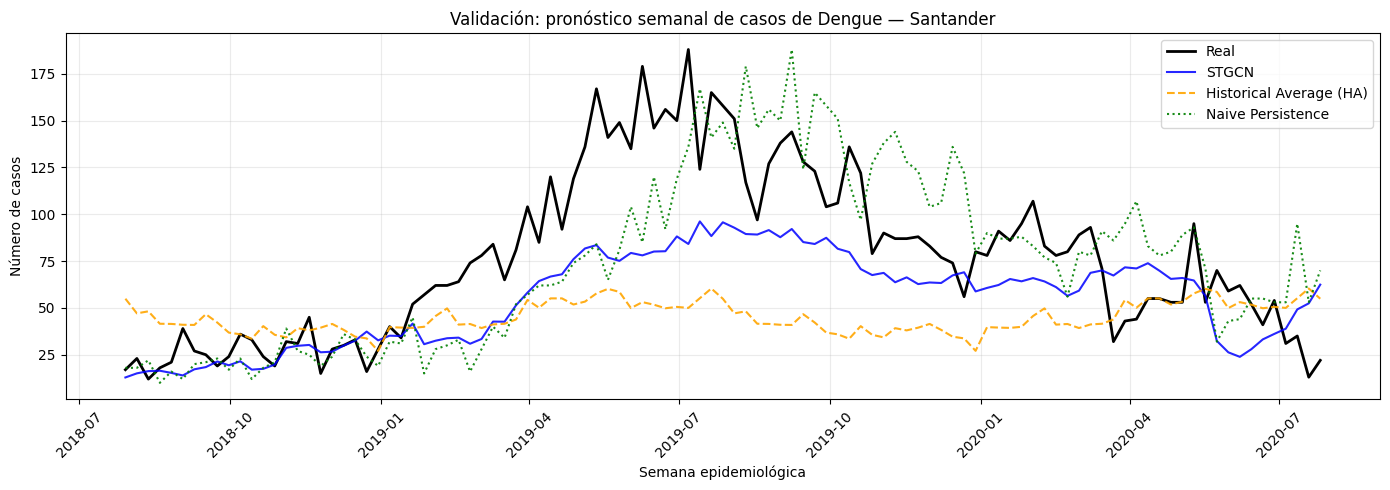

In [12]:
import matplotlib.pyplot as plt

# 1. Predicciones STGCN y objetivos del segmento de validación.
model.eval()
y_true_scaled_parts, y_pred_scaled_parts = [], []
with torch.no_grad():
    for x_batch, y_batch in val_iter:
        y_true_scaled_parts.append(y_batch.cpu().numpy())
        y_pred_scaled_parts.append(model(x_batch).view(len(x_batch), -1).cpu().numpy())
y_true_scaled = np.concatenate(y_true_scaled_parts, axis=0)
y_pred_scaled = np.concatenate(y_pred_scaled_parts, axis=0)
y_real = inverse_log_zscore(y_true_scaled, zscore)
y_stgcn = inverse_log_zscore(y_pred_scaled, zscore)

# 2. Límites temporales y fechas objetivo de validación.
train_end = int(math.floor(len(raw_data) * CONFIG['train_val_test'][0]))
val_len = int(math.floor(len(raw_data) * CONFIG['train_val_test'][1]))
first_val_target = train_end + args.n_his + args.n_pred - 1
raw_frame = pd.read_csv(DATA_DIR / CASE_FILE)
node_names = [c for c in raw_frame.columns if c != 'semana_inicio']

if 'semana_inicio' in raw_frame.columns:
    all_dates = pd.to_datetime(raw_frame['semana_inicio'])
    val_dates = all_dates.iloc[first_val_target:first_val_target + len(y_real)]
else:
    val_dates = pd.Series(range(first_val_target, first_val_target + len(y_real)))

# 3. Historical Average (HA) estacional calculado solo con entrenamiento.
if 'semana_inicio' in raw_frame.columns:
    train_frame = raw_frame.iloc[:train_end].copy()
    train_frame['fecha'] = pd.to_datetime(train_frame['semana_inicio'])
    train_frame['semana_del_anio'] = train_frame['fecha'].dt.isocalendar().week.astype(int)
    ha_estacional = train_frame.groupby('semana_del_anio')[node_names].mean()
    ha_global = raw_data[:train_end].mean(axis=0)

    ha_predictions = []
    for fecha in val_dates:
        week_num = int(pd.Timestamp(fecha).isocalendar().week)
        if week_num in ha_estacional.index:
            ha_predictions.append(ha_estacional.loc[week_num].to_numpy())
        else:
            ha_predictions.append(ha_global)
    y_ha = np.asarray(ha_predictions)
else:
    # Si faltan fechas, el baseline cae al promedio histórico global por nodo.
    ha_global = raw_data[:train_end].mean(axis=0)
    y_ha = np.repeat(ha_global.reshape(1, -1), repeats=len(y_real), axis=0)

# 4. Naive Persistence: último dato observado antes del horizonte objetivo.
first_persistence_source = first_val_target - args.n_pred
y_persistence = raw_data[first_persistence_source:first_persistence_source + len(y_real)]
if len(y_persistence) != len(y_real):
    raise ValueError('No se pudieron alinear las predicciones de persistencia con validación.')

# 5. Métricas calculadas en escala original de casos.
def regression_metrics(y_true, y_hat):
    error = np.abs(y_true - y_hat)
    mse_value = np.mean((y_true - y_hat) ** 2)
    mae_value = np.mean(error)
    rmse_value = np.sqrt(mse_value)
    denominator = np.sum(np.abs(y_true))
    wmape_value = np.sum(error) / (denominator + 1e-5)
    return {'MSE': mse_value, 'MAE': mae_value, 'RMSE': rmse_value, 'WMAPE': wmape_value}

comparison_val = pd.DataFrame([
    {'Modelo': 'STGCN', **regression_metrics(y_real, y_stgcn)},
    {'Modelo': 'Historical Average (HA)', **regression_metrics(y_real, y_ha)},
    {'Modelo': 'Naive Persistence', **regression_metrics(y_real, y_persistence)},
])
print('Métricas del segmento de VALIDACIÓN:')
display(comparison_val)

# 6. Gráfico de validación para el departamento elegido.
NODE_TO_PLOT = 'Santander'
if isinstance(NODE_TO_PLOT, str):
    if NODE_TO_PLOT not in node_names:
        raise ValueError(f"'{NODE_TO_PLOT}' no está entre las columnas de departamentos.")
    node_index = node_names.index(NODE_TO_PLOT)
else:
    node_index = int(NODE_TO_PLOT)
    if not 0 <= node_index < n_vertex:
        raise IndexError(f'NODE_TO_PLOT debe estar entre 0 y {n_vertex - 1}.')
node_label = node_names[node_index]

plt.figure(figsize=(14, 5))
plt.plot(val_dates, y_real[:, node_index], label='Real', linewidth=2, color='black')
plt.plot(val_dates, y_stgcn[:, node_index], label='STGCN', alpha=0.85, color='blue')
plt.plot(val_dates, y_ha[:, node_index], label='Historical Average (HA)', linestyle='--', alpha=0.9, color='orange')
plt.plot(val_dates, y_persistence[:, node_index], label='Naive Persistence', linestyle=':', alpha=0.9, color='green')
plt.title(f'Validación: pronóstico semanal de casos de Dengue — {node_label}')
plt.xlabel('Semana epidemiológica')
plt.ylabel('Número de casos')
plt.legend()
plt.grid(True, alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Métricas del segmento de PRUEBA (TEST):


,Modelo,MSE,MAE,RMSE,WMAPE
0,STGCN,1209.462402,12.692744,34.777325,0.532461
1,Historical Average (HA),1860.207137,20.538910,43.130119,0.861607
2,Naive Persistence,1038.557495,12.480846,32.226658,0.523571


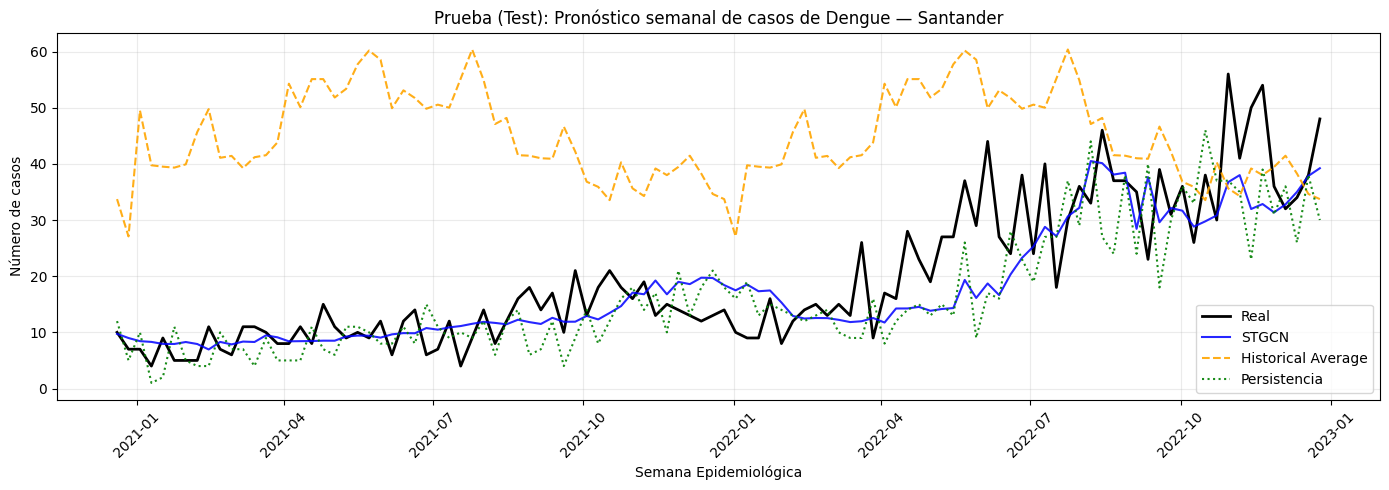

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import math

# --- SECCIÓN AJUSTADA: Definir node_names al inicio para usarlo en el HA ---
raw_frame = pd.read_csv(DATA_DIR / CASE_FILE)
node_names = [c for c in raw_frame.columns if c != 'semana_inicio']

# 1. Predicciones STGCN y objetivos de la prueba
model.eval()
y_true_scaled_parts, y_pred_scaled_parts = [], []
with torch.no_grad():
    for x_batch, y_batch in test_iter:
        y_true_scaled_parts.append(y_batch.cpu().numpy())
        y_pred_scaled_parts.append(model(x_batch).view(len(x_batch), -1).cpu().numpy())

y_true_scaled = np.concatenate(y_true_scaled_parts, axis=0)
y_pred_scaled = np.concatenate(y_pred_scaled_parts, axis=0)

# --- CORRECCIÓN: Usar la misma función que en validación ---
y_real = inverse_log_zscore(y_true_scaled, zscore)
y_stgcn = inverse_log_zscore(y_pred_scaled, zscore)
# Si tu pipeline estándar cambió y ahora de verdad usas zscore.inverse_transform, 
# entonces cámbialo, pero asegúrate de que sea consistente.

# 2. Definir límites e índices temporales
train_end = int(math.floor(len(raw_data) * CONFIG['train_val_test'][0]))
val_end = int(math.floor(len(raw_data) * CONFIG['train_val_test'][1]))
first_test_target = train_end + val_end + args.n_his + args.n_pred - 1

if 'semana_inicio' in raw_frame.columns:
    all_dates = pd.to_datetime(raw_frame['semana_inicio'])
    test_dates = all_dates.iloc[first_test_target : first_test_target + len(y_real)]
else:
    test_dates = pd.Series(range(first_test_target, first_test_target + len(y_real)))

# 3. Cálculo del Historical Average (HA) Estacional
if 'semana_inicio' in raw_frame.columns:
    train_frame = raw_frame.iloc[:train_end].copy()
    train_frame['fecha'] = pd.to_datetime(train_frame['semana_inicio'])
    train_frame['semana_del_anio'] = train_frame['fecha'].dt.isocalendar().week.astype(int)

    # --- CORRECCIÓN: Filtrar por [node_names] para evitar dimensiones incorrectas ---
    ha_estacional = train_frame.groupby('semana_del_anio')[node_names].mean()
    ha_global = raw_data[:train_end].mean(axis=0)

    y_ha_lista = []
    for fecha in test_dates:
        semana_actual = int(pd.Timestamp(fecha).isocalendar().week)
        if semana_actual in ha_estacional.index:
            y_ha_lista.append(ha_estacional.loc[semana_actual].to_numpy())
        else:
            y_ha_lista.append(ha_global)
    
    y_ha = np.array(y_ha_lista)
else:
    ha_global = raw_data[:train_end].mean(axis=0)
    y_ha = np.repeat(ha_global.reshape(1, -1), repeats=len(y_real), axis=0)

# 4. Cálculo del Baseline de Persistencia (Naive Persistence)
start_pers_idx = first_test_target - args.n_pred
end_pers_idx = start_pers_idx + len(y_real)
y_persistence = raw_data[start_pers_idx:end_pers_idx]

if len(y_persistence) != len(y_real):
    raise ValueError('No se pudieron alinear las predicciones de persistencia con prueba.')

# 5. Cálculo de métricas
def regression_metrics(y_true, y_hat):
    error = np.abs(y_true - y_hat)
    mse_value = np.mean((y_true - y_hat) ** 2)
    mae_value = np.mean(error)
    rmse_value = np.sqrt(mse_value)
    denominator = np.sum(np.abs(y_true))
    wmape_value = np.sum(error) / (denominator + 1e-5) 
    return {'MSE': mse_value, 'MAE': mae_value, 'RMSE': rmse_value, 'WMAPE': wmape_value}

# Imprimir la tabla comparativa
comparison = pd.DataFrame([
    {'Modelo': 'STGCN', **regression_metrics(y_real, y_stgcn)},
    {'Modelo': 'Historical Average (HA)', **regression_metrics(y_real, y_ha)},
    {'Modelo': 'Naive Persistence', **regression_metrics(y_real, y_persistence)},
])
print('Métricas del segmento de PRUEBA (TEST):')
display(comparison)

# 6. Graficar resultados
NODE_TO_PLOT = 'Santander'

if isinstance(NODE_TO_PLOT, str):
    if NODE_TO_PLOT not in node_names:
        raise ValueError(f"'{NODE_TO_PLOT}' no está entre las columnas de departamentos.")
    node_index = node_names.index(NODE_TO_PLOT)
else:
    node_index = int(NODE_TO_PLOT)
    # Nota: Asegúrate de que n_vertex esté definido previamente en tu entorno
    if not 0 <= node_index < n_vertex: 
        raise IndexError(f'NODE_TO_PLOT debe estar entre 0 y {n_vertex - 1}.')

node_label = node_names[node_index]

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_real[:, node_index], label='Real', linewidth=2, color='black')
plt.plot(test_dates, y_stgcn[:, node_index], label='STGCN', alpha=0.85, color='blue')
plt.plot(test_dates, y_ha[:, node_index], label='Historical Average', linestyle='--', alpha=0.9, color='orange')
plt.plot(test_dates, y_persistence[:, node_index], label='Persistencia', linestyle=':', alpha=0.9, color='green')

plt.title(f'Prueba (Test): Pronóstico semanal de casos de Dengue — {node_label}')
plt.xlabel('Semana Epidemiológica')
plt.ylabel('Número de casos')
plt.legend()
plt.grid(True, alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
import numpy as np
import pandas as pd
import math
from scipy.stats import ks_2samp, wasserstein_distance

# 1. Definir los cortes de tiempo
train_end = int(math.floor(len(raw_data) * CONFIG['train_val_test'][0]))
val_len = int(math.floor(len(raw_data) * CONFIG['train_val_test'][1]))
test_start = train_end + val_len

# 2. Separar crudos (Semanas x Nodos)
train_data = raw_data[:train_end]
test_data = raw_data[test_start:]

n_nodes = raw_data.shape[1]
ood_results = []

# Aseguramos tener los nombres correctos sin la columna de fechas
if 'node_names' not in globals():
    node_names = [c for c in raw_frame.columns if c != 'semana_inicio']

for i in range(n_nodes):
    train_node = train_data[:, i]
    test_node = test_data[:, i]
    
    # Análisis Descriptivo
    mean_train, std_train, max_train = np.mean(train_node), np.std(train_node), np.max(train_node)
    mean_test, std_test, max_test = np.mean(test_node), np.std(test_node), np.max(test_node)
    
    # Pruebas Estadísticas
    # KS-Test: p-value < 0.05 indica distribuciones diferentes
    ks_stat, p_value = ks_2samp(train_node, test_node)
    # Wasserstein: Mayor valor = mayor divergencia OOD
    w_dist = wasserstein_distance(train_node, test_node)
    
    ood_results.append({
        'Departamento': node_names[i] if i < len(node_names) else f'Nodo {i}',
        'Max_Train': max_train,
        'Max_Test': max_test,
        'Media_Train': round(mean_train, 2),
        'Media_Test': round(mean_test, 2),
        'Shift_Media': f"{round((mean_test - mean_train) / (mean_train + 1e-5) * 100, 1)}%",
        'KS_p_value': round(p_value, 4),
        'Wasserstein_Dist': round(w_dist, 2), # <- Agregado a la tabla
        'OOD_Confirmado': 'Sí' if p_value < 0.05 or max_test > max_train else 'No'
    })

df_ood = pd.DataFrame(ood_results)
print("Análisis Out-Of-Distribution (OOD) entre Train y Test:")
display(df_ood)

Análisis Out-Of-Distribution (OOD) entre Train y Test:


,Departamento,Max_Train,Max_Test,Media_Train,Media_Test,Shift_Media,KS_p_value,Wasserstein_Dist,OOD_Confirmado
0,Amazonas,17.0,15.0,1.210000,4.330000,259.5%,0.0000,3.13,Sí
1,Antioquia,618.0,82.0,68.980003,23.450001,-66.0%,0.0000,47.22,Sí
2,Arauca,155.0,22.0,12.030000,3.610000,-70.0%,0.0000,8.42,Sí
3,Atlántico,258.0,558.0,43.689999,135.320007,209.6999969482422%,0.0000,91.63,Sí
4,Bogotá D.C.,255.0,15.0,18.200001,4.720000,-74.0999984741211%,0.0000,13.48,Sí
5,Bolívar,133.0,310.0,17.209999,84.750000,392.3999938964844%,0.0000,67.54,Sí
6,Boyacá,94.0,15.0,12.060000,4.590000,-62.0%,0.0000,7.48,Sí
7,Caldas,79.0,13.0,8.290000,2.480000,-70.0999984741211%,0.0000,5.82,Sí
8,Caquetá,80.0,43.0,7.240000,10.630000,46.79999923706055%,0.0005,3.86,Sí
9,Casanare,76.0,105.0,10.040000,21.160000,110.80000305175781%,0.0030,11.12,Sí


Split: (0.7, 0.15, 0.15)
Test desde 2020-12-20 00:00:00 hasta 2022-12-25 00:00:00
Ajustando ARIMA por departamento (puede tardar ~30 s)...
Métricas del segmento de PRUEBA (TEST):


,Modelo,MSE,MAE,RMSE,WMAPE
0,STGCN,1209.462402,12.692744,34.777325,0.532461
1,"ARIMA(2,1,2)",1105.709635,12.582402,33.252212,0.527832
2,Historical Average (HA),1860.207137,20.538910,43.130119,0.861607
3,Naive Persistence,1038.557495,12.480846,32.226658,0.523571


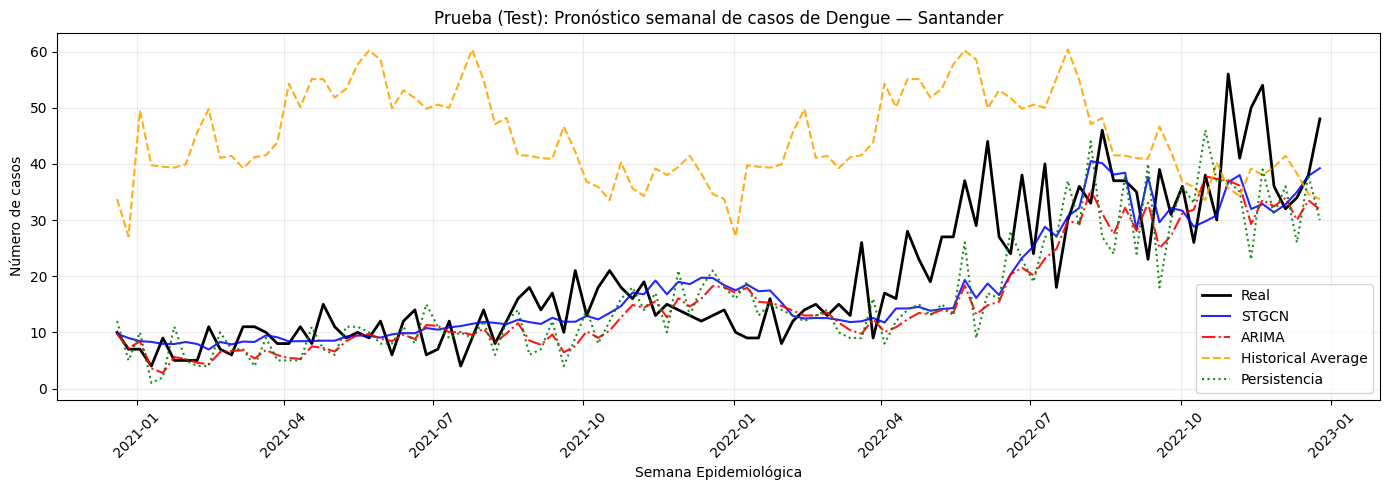

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import math
import warnings
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")


# ---------------------------------------------------------------
# Baseline ARIMA: un modelo por departamento, sin fuga de información
# ---------------------------------------------------------------
def arima_forecast(raw_data, train_end, first_test_target, n_test, n_pred,
                   order=(2, 1, 2), use_log=True):
    raw_data = np.asarray(raw_data, dtype=float)
    T, n_nodes = raw_data.shape
    data = np.log1p(raw_data) if use_log else raw_data
    y_arima = np.zeros((n_test, n_nodes))

    for j in range(n_nodes):
        serie = data[:, j]
        try:
            base = ARIMA(serie[:train_end], order=order).fit()  # ajuste único con train
        except Exception:
            base = None  # fallback a persistencia para este nodo
        for i in range(n_test):
            origen = first_test_target + i - n_pred  # último índice observado
            if base is None:
                y_arima[i, j] = serie[origen]
            else:
                res = base.append(serie[train_end:origen + 1], refit=False)
                y_arima[i, j] = res.forecast(steps=n_pred)[-1]

    if use_log:
        y_arima = np.expm1(y_arima)
    return np.clip(y_arima, 0, None)


# --- Definir node_names al inicio para usarlo en el HA ---
raw_frame = pd.read_csv(DATA_DIR / CASE_FILE)
node_names = [c for c in raw_frame.columns if c != 'semana_inicio']

# 1. Predicciones STGCN y objetivos de la prueba
model.eval()
y_true_scaled_parts, y_pred_scaled_parts = [], []
with torch.no_grad():
    for x_batch, y_batch in test_iter:
        y_true_scaled_parts.append(y_batch.cpu().numpy())
        y_pred_scaled_parts.append(model(x_batch).view(len(x_batch), -1).cpu().numpy())

y_true_scaled = np.concatenate(y_true_scaled_parts, axis=0)
y_pred_scaled = np.concatenate(y_pred_scaled_parts, axis=0)

y_real = inverse_log_zscore(y_true_scaled, zscore)
y_stgcn = inverse_log_zscore(y_pred_scaled, zscore)

# 2. Definir límites e índices temporales
train_end = int(math.floor(len(raw_data) * CONFIG['train_val_test'][0]))
val_end = int(math.floor(len(raw_data) * CONFIG['train_val_test'][1]))
first_test_target = train_end + val_end + args.n_his + args.n_pred - 1

if 'semana_inicio' in raw_frame.columns:
    all_dates = pd.to_datetime(raw_frame['semana_inicio'])
    test_dates = all_dates.iloc[first_test_target : first_test_target + len(y_real)]
else:
    test_dates = pd.Series(range(first_test_target, first_test_target + len(y_real)))

# Chequeo de alineación (la última fecha debería ser 2022-12-25)
print('Split:', CONFIG['train_val_test'])
print('Test desde', test_dates.iloc[0], 'hasta', test_dates.iloc[-1])

# 3. Historical Average (HA) Estacional
if 'semana_inicio' in raw_frame.columns:
    train_frame = raw_frame.iloc[:train_end].copy()
    train_frame['fecha'] = pd.to_datetime(train_frame['semana_inicio'])
    train_frame['semana_del_anio'] = train_frame['fecha'].dt.isocalendar().week.astype(int)

    ha_estacional = train_frame.groupby('semana_del_anio')[node_names].mean()
    ha_global = raw_data[:train_end].mean(axis=0)

    y_ha_lista = []
    for fecha in test_dates:
        semana_actual = int(pd.Timestamp(fecha).isocalendar().week)
        if semana_actual in ha_estacional.index:
            y_ha_lista.append(ha_estacional.loc[semana_actual].to_numpy())
        else:
            y_ha_lista.append(ha_global)

    y_ha = np.array(y_ha_lista)
else:
    ha_global = raw_data[:train_end].mean(axis=0)
    y_ha = np.repeat(ha_global.reshape(1, -1), repeats=len(y_real), axis=0)

# 4. Baseline de Persistencia (Naive Persistence)
start_pers_idx = first_test_target - args.n_pred
end_pers_idx = start_pers_idx + len(y_real)
y_persistence = raw_data[start_pers_idx:end_pers_idx]

if len(y_persistence) != len(y_real):
    raise ValueError('No se pudieron alinear las predicciones de persistencia con prueba.')

# 5. Baseline ARIMA
print('Ajustando ARIMA por departamento (puede tardar ~30 s)...')
y_arima = arima_forecast(
    raw_data, train_end, first_test_target,
    n_test=len(y_real), n_pred=args.n_pred, order=(2, 1, 2)
)

# 6. Métricas
def regression_metrics(y_true, y_hat):
    error = np.abs(y_true - y_hat)
    mse_value = np.mean((y_true - y_hat) ** 2)
    mae_value = np.mean(error)
    rmse_value = np.sqrt(mse_value)
    denominator = np.sum(np.abs(y_true))
    wmape_value = np.sum(error) / (denominator + 1e-5)
    return {'MSE': mse_value, 'MAE': mae_value, 'RMSE': rmse_value, 'WMAPE': wmape_value}

comparison = pd.DataFrame([
    {'Modelo': 'STGCN', **regression_metrics(y_real, y_stgcn)},
    {'Modelo': 'ARIMA(2,1,2)', **regression_metrics(y_real, y_arima)},
    {'Modelo': 'Historical Average (HA)', **regression_metrics(y_real, y_ha)},
    {'Modelo': 'Naive Persistence', **regression_metrics(y_real, y_persistence)},
])
print('Métricas del segmento de PRUEBA (TEST):')
display(comparison)

# 7. Graficar resultados
NODE_TO_PLOT = 'Santander'

if isinstance(NODE_TO_PLOT, str):
    if NODE_TO_PLOT not in node_names:
        raise ValueError(f"'{NODE_TO_PLOT}' no está entre las columnas de departamentos.")
    node_index = node_names.index(NODE_TO_PLOT)
else:
    node_index = int(NODE_TO_PLOT)
    if not 0 <= node_index < n_vertex:
        raise IndexError(f'NODE_TO_PLOT debe estar entre 0 y {n_vertex - 1}.')

node_label = node_names[node_index]

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_real[:, node_index], label='Real', linewidth=2, color='black')
plt.plot(test_dates, y_stgcn[:, node_index], label='STGCN', alpha=0.85, color='blue')
plt.plot(test_dates, y_arima[:, node_index], label='ARIMA', linestyle='-.', alpha=0.9, color='red')
plt.plot(test_dates, y_ha[:, node_index], label='Historical Average', linestyle='--', alpha=0.9, color='orange')
plt.plot(test_dates, y_persistence[:, node_index], label='Persistencia', linestyle=':', alpha=0.9, color='green')

plt.title(f'Prueba (Test): Pronóstico semanal de casos de Dengue — {node_label}')
plt.xlabel('Semana Epidemiológica')
plt.ylabel('Número de casos')
plt.legend()
plt.grid(True, alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()